<a href="https://www.kaggle.com/code/aabdollahii/map-digits?scriptVersionId=371560671" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# A , B

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from scipy.special import logsumexp

# Load Digits dataset
digits = load_digits()

# Select only classes 3, 5 and 8
selected_classes = [3, 5, 8]

mask = np.isin(digits.target, selected_classes)

X = digits.data[mask].astype(float)
y = digits.target[mask]

# Display dataset information
print("Dataset loaded successfully!")
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])
print("Selected classes:", np.unique(y))

print("\nNumber of samples in each class:")
for cls in selected_classes:
    print(f"Class {cls}: {np.sum(y == cls)}")


Dataset loaded successfully!
Number of samples: 539
Number of features: 64
Selected classes: [3 5 8]

Number of samples in each class:
Class 3: 183
Class 5: 182
Class 8: 174


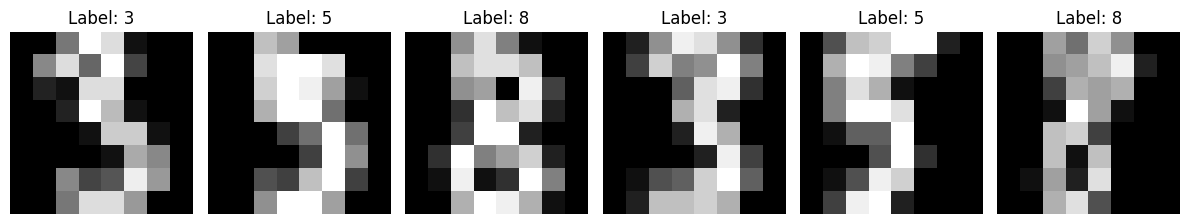

In [2]:

fig, axes = plt.subplots(1, 6, figsize=(12, 3))

for i, ax in enumerate(axes):
    ax.imshow(X[i].reshape(8, 8), cmap="gray")
    ax.set_title(f"Label: {y[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()


In [3]:

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train size:", X_tr.shape[0])
print("Test size:", X_te.shape[0])

print("\nTraining class counts:")
for cls in selected_classes:
    print(cls, np.sum(y_tr == cls))

print("\nTesting class counts:")
for cls in selected_classes:
    print(cls, np.sum(y_te == cls))


Train size: 431
Test size: 108

Training class counts:
3 146
5 146
8 139

Testing class counts:
3 37
5 36
8 35


In [4]:

mu = {}
cov =  {}
prior  = {}

for cls in selected_classes:

    x_c = X_tr[y_tr == cls]

    mu[cls] = np.mean(x_c, axis=0)

    d = x_c - mu[cls]

    cov[cls] = (d.T @ d) / x_c.shape[0]

    cov[cls] += 1e-4 * np.eye(X.shape[1])

    prior[cls] = x_c.shape[0] / X_tr.shape[0]

    print("\nClass:", cls)
    print("Mean shape:", mu[cls].shape)
    print("Covariance shape:", cov[cls].shape)
    print("Prior:", prior[cls])



Class: 3
Mean shape: (64,)
Covariance shape: (64, 64)
Prior: 0.33874709976798145

Class: 5
Mean shape: (64,)
Covariance shape: (64, 64)
Prior: 0.33874709976798145

Class: 8
Mean shape: (64,)
Covariance shape: (64, 64)
Prior: 0.3225058004640371


In [5]:

for cls in selected_classes:

    print("\nClass:", cls)
    print("Prior:", round(prior[cls], 4))
    print("Mean (first 10 features):")
    print(mu[cls][:10])

    print("Covariance (first 3x3):")
    print(cov[cls][:3, :3])

    print("Covariance determinant:")
    print(np.linalg.det(cov[cls]))



Class: 3
Prior: 0.3387
Mean (first 10 features):
[0.00000000e+00 5.89041096e-01 8.50684932e+00 1.42808219e+01
 1.42876712e+01 7.65753425e+00 7.60273973e-01 6.84931507e-03
 1.36986301e-02 4.15753425e+00]
Covariance (first 3x3):
[[1.00000000e-04 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 8.99705930e-01 2.05075999e+00]
 [0.00000000e+00 2.05075999e+00 1.40993682e+01]]
Covariance determinant:
5.800569956472369e-29

Class: 5
Prior: 0.3387
Mean (first 10 features):
[0.00000000e+00 9.17808219e-01 9.96575342e+00 1.29726027e+01
 1.37945205e+01 1.20136986e+01 4.30136986e+00 5.47945205e-02
 6.84931507e-03 3.67123288e+00]
Covariance (first 3x3):
[[1.00000000e-04 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 2.62348150e+00 3.33280165e+00]
 [0.00000000e+00 3.33280165e+00 1.61975573e+01]]
Covariance determinant:
1.977314178269219e-32

Class: 8
Prior: 0.3225
Mean (first 10 features):
[ 0.          0.15827338  5.09352518 11.69784173 12.25899281  6.10071942
  0.58273381  0.          0.02877698  1

In [6]:

log_lik = np.zeros((X_te.shape[0], len(selected_classes)))

for j, cls in enumerate(selected_classes):

    L = np.linalg.cholesky(cov[cls])

    log_det = 2 * np.sum(np.log(np.diag(L)))

    diff = X_te - mu[cls]

    z = np.linalg.solve(L, diff.T)

    q = np.sum(z ** 2, axis=0)

    log_lik[:, j] = -0.5 * (
        X.shape[1] * np.log(2 * np.pi)
        + log_det
        + q
    )

print("Log-Likelihood shape:", log_lik.shape)
print("\nFirst 5 samples:")
print(log_lik[:5])


Log-Likelihood shape: (108, 3)

First 5 samples:
[[ -57.14845932 -278.67027614 -172.26862744]
 [-308.98793908 -218.43043476 -142.95989885]
 [-153.12956776 -315.05012161  -67.59328026]
 [ -58.68424757 -192.80134165 -407.35645421]
 [-121.03277645 -235.66297542  -55.44109893]]


In [7]:

# calculating post
pri = np.zeros(len(selected_classes))

for j, cls in enumerate(selected_classes):
    pri[j] = prior[cls]

log_joint = log_lik + np.log(pri)

log_post = log_joint - logsumexp(
    log_joint,
    axis=1,
    keepdims=True
)

post = np.exp(log_post)

print("Posterior shape:", post.shape)

print("\nFirst 10 posterior probabilities:")
post_df = pd.DataFrame(
    post[:10],
    columns=["P(3|x)", "P(5|x)", "P(8|x)"]
)

print(post_df.round(4))

print("\nPosterior sum (first 5 samples):")
print(np.sum(post[:5], axis=1))


Posterior shape: (108, 3)

First 10 posterior probabilities:
   P(3|x)  P(5|x)  P(8|x)
0     1.0     0.0     0.0
1     0.0     0.0     1.0
2     0.0     0.0     1.0
3     1.0     0.0     0.0
4     0.0     0.0     1.0
5     0.0     0.0     1.0
6     1.0     0.0     0.0
7     1.0     0.0     0.0
8     0.0     1.0     0.0
9     1.0     0.0     0.0

Posterior sum (first 5 samples):
[1. 1. 1. 1. 1.]


In [8]:

cls_arr = np.array(selected_classes)

map_idx = np.argmax(post, axis=1)

y_map = cls_arr[map_idx]

acc_map = np.mean(y_map == y_te)

print("MAP Accuracy:", round(acc_map * 100, 2), "%")

from sklearn.metrics import confusion_matrix

cm_map = confusion_matrix(
    y_te,
    y_map,
    labels=selected_classes
)

cm_map_df = pd.DataFrame(
    cm_map,
    index=selected_classes,
    columns=selected_classes
)

print("\nMAP Confusion Matrix:")
print(cm_map_df)


MAP Accuracy: 97.22 %

MAP Confusion Matrix:
    3   5   8
3  36   1   0
5   1  35   0
8   0   1  34


In [9]:

result = pd.DataFrame({
    "Actual": y_te[:15],
    "Predicted": y_map[:15],
    "P(3)": post[:15, 0],
    "P(5)": post[:15, 1],
    "P(8)": post[:15, 2]
})

print(result.round(4))


    Actual  Predicted    P(3)    P(5)  P(8)
0        3          3  1.0000  0.0000   0.0
1        8          8  0.0000  0.0000   1.0
2        8          8  0.0000  0.0000   1.0
3        3          3  1.0000  0.0000   0.0
4        8          8  0.0000  0.0000   1.0
5        8          8  0.0000  0.0000   1.0
6        3          3  1.0000  0.0000   0.0
7        3          3  1.0000  0.0000   0.0
8        5          5  0.0000  1.0000   0.0
9        3          3  1.0000  0.0000   0.0
10       8          8  0.0000  0.0000   1.0
11       3          3  0.7499  0.2501   0.0
12       8          8  0.0000  0.0000   1.0
13       8          8  0.0000  0.0000   1.0
14       5          5  0.0000  1.0000   0.0


# C

In [10]:
# mat for loss 
lam = np.array([
    [0,   1,   4],
    [1,   0,   4],
    [1,   1,   0],
    [0.4, 0.4, 0.4]
])

print("Cost")
print(lam)



Cost
[[0.  1.  4. ]
 [1.  0.  4. ]
 [1.  1.  0. ]
 [0.4 0.4 0.4]]


In [11]:

risk = post @ lam.T

print("Risk shape:", risk.shape)

print("\nFirst 10 samples:")
risk_df = pd.DataFrame(
    risk[:10],
    columns=["Risk_3", "Risk_5", "Risk_8", "Risk_Reject"]
)

print(risk_df.round(6))


Risk shape: (108, 4)

First 10 samples:
   Risk_3  Risk_5  Risk_8  Risk_Reject
0     0.0     1.0     1.0          0.4
1     4.0     4.0     0.0          0.4
2     4.0     4.0     0.0          0.4
3     0.0     1.0     1.0          0.4
4     4.0     4.0     0.0          0.4
5     4.0     4.0     0.0          0.4
6     0.0     1.0     1.0          0.4
7     0.0     1.0     1.0          0.4
8     1.0     0.0     1.0          0.4
9     0.0     1.0     1.0          0.4


In [12]:

dec = np.array(["3", "5", "8", "Reject"])

mr_idx = np.argmin(risk, axis=1)

y_mr = dec[mr_idx]

min_risk = risk[np.arange(len(risk)),mr_idx]

print(" Minimum Risk Predictions:")
print(y_mr[:20])

print("\n Decision counts:")
for name in dec:
    print(name, np.sum(y_mr == name))

print("\n Average minimum conditional risk:")
print(np.mean(min_risk))


 Minimum Risk Predictions:
['3' '8' '8' '3' '8' '8' '3' '3' '5' '3' '8' '3' '8' '8' '5' '5' '5' '5'
 '8' '5']

 Decision counts:
3 37
5 37
8 34
Reject 0

 Average minimum conditional risk:
0.002316329839301882


In [13]:

mr_result = pd.DataFrame({
    "Actual": y_te[:15],
    "MAP": y_map[:15],
    "MinRisk": y_mr[:15],
    "Risk_3": risk[:15, 0],
    "Risk_5": risk[:15, 1],
    "Risk_8": risk[:15, 2],
    "Risk_Reject": risk[:15, 3]
})

print(mr_result.round(4))


    Actual  MAP MinRisk  Risk_3  Risk_5  Risk_8  Risk_Reject
0        3    3       3  0.0000  1.0000     1.0          0.4
1        8    8       8  4.0000  4.0000     0.0          0.4
2        8    8       8  4.0000  4.0000     0.0          0.4
3        3    3       3  0.0000  1.0000     1.0          0.4
4        8    8       8  4.0000  4.0000     0.0          0.4
5        8    8       8  4.0000  4.0000     0.0          0.4
6        3    3       3  0.0000  1.0000     1.0          0.4
7        3    3       3  0.0000  1.0000     1.0          0.4
8        5    5       5  1.0000  0.0000     1.0          0.4
9        3    3       3  0.0000  1.0000     1.0          0.4
10       8    8       8  4.0000  4.0000     0.0          0.4
11       3    3       3  0.2501  0.7499     1.0          0.4
12       8    8       8  4.0000  4.0000     0.0          0.4
13       8    8       8  4.0000  4.0000     0.0          0.4
14       5    5       5  1.0000  0.0000     1.0          0.4


# D 

In [14]:

n = len(y_te)

true_idx = np.zeros(n, dtype=int)

for j, cls in enumerate(cls_arr):
    true_idx[y_te == cls] = j

rej = y_mr == "Reject"
keep = ~rej

ok_map = y_map == y_te
ok_mr = y_mr == y_te.astype(str)

acc_map = np.mean(ok_map)
acc_mr = np.mean(ok_mr[keep]) if np.any(keep) else np.nan

cov_map = 1.0
cov_mr = np.mean(keep)

rr_map = 0.0
rr_mr = np.mean(rej)

r_map = np.mean(risk[np.arange(n), map_idx])
r_mr = np.mean(risk[np.arange(n), mr_idx])

emp_map = np.mean(lam[map_idx, true_idx])
emp_mr = np.mean(lam[mr_idx, true_idx])

res = pd.DataFrame({
    "MAP": [acc_map, cov_map, rr_map, r_map, emp_map],
    "MinRisk": [acc_mr, cov_mr, rr_mr, r_mr, emp_mr]
}, index=[
    "Accuracy",
    "Coverage",
    "Rejection Rate",
    "Expected Risk (posterior)",
    "Empirical Risk"
])

print(res.round(4))

print("\nDifferent decisions:")
print(np.sum(y_map.astype(str) != y_mr))

print("\nMR Accuracy over all samples:")
print(round(np.mean(ok_mr), 4))


                              MAP  MinRisk
Accuracy                   0.9722   0.9722
Coverage                   1.0000   1.0000
Rejection Rate             0.0000   0.0000
Expected Risk (posterior)  0.0023   0.0023
Empirical Risk             0.0556   0.0556

Different decisions:
0

MR Accuracy over all samples:
0.9722


In [15]:

cm_mr = pd.crosstab(
    pd.Series(y_te, name="Actual"),
    pd.Series(y_mr, name="Decision")
)

cm_mr = cm_mr.reindex(
    index=selected_classes,
    columns=["3", "5", "8", "Reject"],
    fill_value=0
)

print("MAP Confusion Matrix:")
print(cm_map_df)

print("\nMinimum Risk Confusion Matrix:")
print(cm_mr)


MAP Confusion Matrix:
    3   5   8
3  36   1   0
5   1  35   0
8   0   1  34

Minimum Risk Confusion Matrix:
Decision   3   5   8  Reject
Actual                      
3         36   1   0       0
5          1  35   0       0
8          0   1  34       0


# E

In [16]:

costs = [0.1, 0.4, 0.8]

out = []

for c_rej in costs:

    lam_c = lam.copy()
    lam_c[3, :] = c_rej

    risk_c = post @ lam_c.T

    idx_c = np.argmin(risk_c, axis=1)
    pred_c = dec[idx_c]

    rej_c = pred_c == "Reject"
    keep_c = ~rej_c

    ok_c = pred_c == y_te.astype(str)

    acc_all = np.mean(ok_c)

    if np.any(keep_c):
        acc_sel = np.mean(ok_c[keep_c])
    else:
        acc_sel = np.nan

    cov_c = np.mean(keep_c)
    rr_c = np.mean(rej_c)

    exp_c = np.mean(
        risk_c[np.arange(n), idx_c]
    )

    emp_c = np.mean(
        lam_c[idx_c, true_idx]
    )

    out.append({
        "RejectCost": c_rej,
        "N_3": np.sum(pred_c == "3"),
        "N_5": np.sum(pred_c == "5"),
        "N_8": np.sum(pred_c == "8"),
        "N_Reject": np.sum(rej_c),
        "Accuracy_all": acc_all,
        "Accuracy_accepted": acc_sel,
        "Coverage": cov_c,
        "RejectionRate": rr_c,
        "ExpectedRisk": exp_c,
        "EmpiricalRisk": emp_c
    })

    print("\nReject Cost:", c_rej)
    print("Decision counts:")
    print("3:", np.sum(pred_c == "3"))
    print("5:", np.sum(pred_c == "5"))
    print("8:", np.sum(pred_c == "8"))
    print("Reject:", np.sum(rej_c))

    if np.isclose(c_rej, 0.4):
        print("Same predictions as previous MR:",
              np.array_equal(pred_c, y_mr))

res_e = pd.DataFrame(out)

print("\nFinal Comparison:")
print(res_e.round(4).to_string(index=False))



Reject Cost: 0.1
Decision counts:
3: 36
5: 37
8: 34
Reject: 1

Reject Cost: 0.4
Decision counts:
3: 37
5: 37
8: 34
Reject: 0
Same predictions as previous MR: True

Reject Cost: 0.8
Decision counts:
3: 37
5: 37
8: 34
Reject: 0

Final Comparison:
 RejectCost  N_3  N_5  N_8  N_Reject  Accuracy_all  Accuracy_accepted  Coverage  RejectionRate  ExpectedRisk  EmpiricalRisk
        0.1   36   37   34         1        0.9630             0.9720    0.9907         0.0093        0.0009         0.0565
        0.4   37   37   34         0        0.9722             0.9722    1.0000         0.0000        0.0023         0.0556
        0.8   37   37   34         0        0.9722             0.9722    1.0000         0.0000        0.0023         0.0556


In [17]:

for c_rej in costs:

    lam_c = lam.copy()
    lam_c[3, :] = c_rej

    risk_c = post @ lam_c.T

    idx_c = np.argmin(risk_c, axis=1)
    pred_c = dec[idx_c]

    cm_c = pd.crosstab(
        pd.Series(y_te, name="Actual"),
        pd.Series(pred_c, name="Decision")
    )

    cm_c = cm_c.reindex(
        index=selected_classes,
        columns=["3", "5", "8", "Reject"],
        fill_value=0
    )

    print("\nReject Cost:", c_rej)
    print(cm_c)



Reject Cost: 0.1
Decision   3   5   8  Reject
Actual                      
3         35   1   0       1
5          1  35   0       0
8          0   1  34       0

Reject Cost: 0.4
Decision   3   5   8  Reject
Actual                      
3         36   1   0       0
5          1  35   0       0
8          0   1  34       0

Reject Cost: 0.8
Decision   3   5   8  Reject
Actual                      
3         36   1   0       0
5          1  35   0       0
8          0   1  34       0
